In [7]:
import pandas as pd
from eda_manager.data_type import summarize_dataframe
from helper import read_json_to_dict
from eda_manager.chart.chart_handler import select_column_info
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.font_manager as fm
from eda_manager.chart.chart_helper import formatter_kmb
import seaborn as sns
from fonts import get_project_font
from eda_manager.chart.relative.relative_dict import decode_ui_chart_opiton, encode_ui_chart_option
from eda_manager.chart.chart_helper import (init_figure_axes,
                                            update_chart_with_common_option,
                                            save_chart_to_bytes, save_gif_chart_to_bytes,
                                            close_pyplot)

FONT_GOTHIC_PATH, FONT_DREAM_PATH = get_project_font()

matplotlib.use("agg")
DBGOTHIC = fm.FontProperties(fname=FONT_GOTHIC_PATH)
DBDREAM = fm.FontProperties(fname=FONT_DREAM_PATH)
fm.fontManager.addfont(FONT_GOTHIC_PATH)
fm.fontManager.addfont(FONT_DREAM_PATH)

plt.rcParams['font.family'] = DBGOTHIC.get_name()
plt.rcParams['axes.unicode_minus'] = False

In [10]:
%matplotlib inline

In [15]:
project_dir=r"C:\Users\10007166\insightmaker_project\Fabout CTPL 분석"
x_num="CTPL"
y_num="QTY"
z_num="Period"
g_cat="Product Group"
color="#0f0f0f80"
legend_pos = "best"
marker="D"
marker_size=10

z_angle=45
data_path = os.path.join(project_dir, "data.pkl")
df = pd.read_pickle(data_path)[[x_num, y_num, z_num, g_cat]]

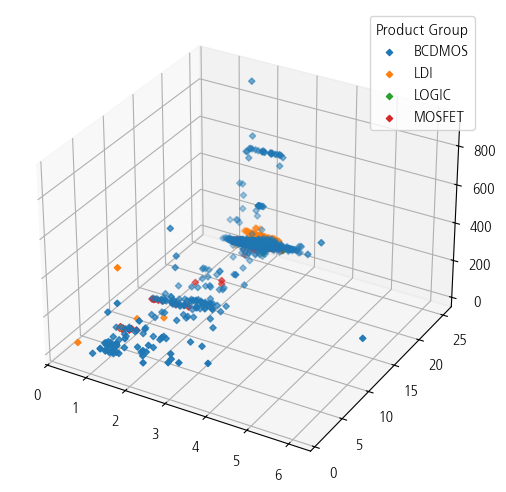

In [16]:
group_size = len(df[g_cat].unique())
if group_size<=10:
    cmap = plt.get_cmap("tab10")
elif group_size<=20:
    cmap = plt.get_cmap("tab20")
else:
    cmap = plt.cm.viridis
    cmap = cmap(np.linspace(0, 1, group_size))
    cmap = [tuple(color) for color in cmap]
fig, ax = init_figure_axes("auto", "auto", dimension="3d")
for i, (group, data) in enumerate(df.groupby(g_cat)):
    options = {
        "xs": data[x_num].values,
        "ys": data[y_num].values,
        "zs": data[z_num].values,
        "c": cmap(i) if group_size<=20 else cmap[i],
        "label": group
    }
    if marker!="auto":
        options.update({"marker": marker})
    if marker_size!="auto":
        options.update({"s": marker_size})
    ax.scatter(**options)
if legend_pos != "auto":
    ax.legend(title=g_cat, loc=legend_pos)
plt.show()

In [ ]:
option = {
    "project_dir": r"C:\Users\10007166\insightmaker_project\Fabout CTPL 분석",
    "x_num": "CTPL",
    "y_num": "QTY",
    "z_num": "Total Layer",
    "g_cat": "Product Group",
    "legend_pos": "auto", # 'best', 'upper left', 'upper right', 'upper center', 'lower left', 'lower right', 'lower center
    "marker": "auto",
    "marker_size": "auto",
    # "gif": True,
    "gif": False,
    "rotate_axis": "horizontal",
    "chart_nm": "auto",
    "x_axis_nm": "CTPL Custom",
    "y_axis_nm": "auto",
    "z_axis_nm": "auto",
    "x_axis_rotate": "auto",
    "y_axis_rotate": "auto",
    "z_axis_rotate": "auto",
    "x_size": "auto",
    "y_size": "auto"
}

df = pd.read_pickle(data_path)[[x_num, y_num, z_num]]
auto_title = f"산점도 - {x_num} vs {y_num} vs {x_num}"
options = {
    "xs": df[x_num].values,
    "ys": df[y_num].values,
    "zs": df[z_num].values,
}
if marker!="auto":
    options.update({"marker": marker})
if marker_size!="auto":
    options.update({"s":marker_size})

size_x, size_y = common_option['x_size'], common_option['y_size']
fig, ax = init_figure_axes(size_x, size_y, dimension="3d")
ax.scatter(**options)